# Dataset original

In [1]:
from pathlib import Path
import pandas as pd

# Encontrar a raiz do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Caminho do dataset original
caminho_csv = raiz / "data" / "raw" / "payflow_credit_risk.csv"

# Carregar os dados
df = pd.read_csv(caminho_csv)

print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

display(df.head())

Linhas: 5000
Colunas: 23


,id_cliente,idade,renda_mensal,tempo_emprego_anos,autonomo,score_credito,valor_solicitado,prazo_meses,juros_mensal_pct,qtde_cartoes,...,dias_atraso_max_12m,reclamacoes_6m,possui_avalista,canal_aquisicao,regiao,tipo_produto,parcelas_pagas_ate_3m,atraso_primeira_parcela_dias,status_apos_90d,default_90d
0,1,22,2639.75,2.718888,0,617.0,2619.14,12,3.96,3,...,0,0,0,site,Sul,emprestimo_pessoal,0,29,default,1
1,2,59,2482.34,10.785992,0,619.0,9101.21,36,3.37,2,...,0,0,0,app,Sudeste,cartao,2,10,em_dia,0
2,3,52,6230.69,9.547608,0,665.0,13258.67,48,3.12,0,...,0,0,0,loja,Sudeste,cartao,2,0,em_dia,0
3,4,41,6469.45,4.287084,0,676.0,1407.28,12,1.52,2,...,90,1,0,parceiro,Sudeste,emprestimo_pessoal,3,0,em_dia,0
4,5,40,2343.04,0.000000,0,671.0,2647.92,48,3.07,1,...,15,0,0,app,Nordeste,bnpl,2,10,em_atraso_leve,0


# Separar features e target
O modelo precisa prever a inadimplência utilizando somente informações que poderiam ser conhecidas no momento da solicitação.

Remove as três variáveis com leakage, o identificador e, preventivamente, a taxa de juros, cuja disponibilidade no momento da decisão não foi confirmada. Separa a variável-alvo.

In [2]:
# Variáveis que não serão utilizadas como preditoras
colunas_excluidas = [
    "id_cliente",
    "default_90d",
    "parcelas_pagas_ate_3m",
    "atraso_primeira_parcela_dias",
    "status_apos_90d",
    "juros_mensal_pct"
]

# Verificar se todas as colunas existem
faltantes = set(colunas_excluidas) - set(df.columns)

if faltantes:
    raise ValueError(f"Colunas não encontradas: {faltantes}")

# Separar variáveis preditoras e alvo
X = df.drop(columns=colunas_excluidas).copy()
y = df["default_90d"].copy()

# Conferir dimensões
print("Features:", X.shape)
print("Target:", y.shape)

display(X.head())

Features: (5000, 17)
Target: (5000,)


,idade,renda_mensal,tempo_emprego_anos,autonomo,score_credito,valor_solicitado,prazo_meses,qtde_cartoes,qtde_contratos_abertos,utilizacao_credito,inadimplencias_anteriores,dias_atraso_max_12m,reclamacoes_6m,possui_avalista,canal_aquisicao,regiao,tipo_produto
0,22,2639.75,2.718888,0,617.0,2619.14,12,3,0,0.012,1,0,0,0,site,Sul,emprestimo_pessoal
1,59,2482.34,10.785992,0,619.0,9101.21,36,2,2,0.282,1,0,0,0,app,Sudeste,cartao
2,52,6230.69,9.547608,0,665.0,13258.67,48,0,2,0.120,0,0,0,0,loja,Sudeste,cartao
3,41,6469.45,4.287084,0,676.0,1407.28,12,2,3,0.670,0,90,1,0,parceiro,Sudeste,emprestimo_pessoal
4,40,2343.04,0.000000,0,671.0,2647.92,48,1,0,0.325,0,15,0,0,app,Nordeste,bnpl


# Separar treinamento e teste
Precisamos avaliar posteriormente o modelo com dados que não foram utilizados para ajustá-lo. A separação deve ocorrer antes da imputação e da padronização.

Divide os registros em 80% para treinamento e 20% para teste, preservando aproximadamente a proporção de inadimplentes por meio da estratificação.

In [3]:
from sklearn.model_selection import train_test_split

# Dividir os dados preservando a proporção das classes
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Conferir as dimensões
print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

# Conferir a proporção de default
print(
    "Default no treino:",
    round(y_treino.mean() * 100, 2),
    "%"
)

print(
    "Default no teste:",
    round(y_teste.mean() * 100, 2),
    "%"
)

Treinamento: (4000, 17)
Teste: (1000, 17)
Default no treino: 12.18 %
Default no teste: 12.2 %


# Identificar os tipos de variáveis
Cada tipo exige um tratamento diferente. Por exemplo, renda_mensal pode ser padronizada, enquanto tipo_produto precisa ser codificada.

Separa as variáveis numéricas das categóricas no conjunto de treinamento.

In [4]:
# Identificar os tipos de variáveis
colunas_numericas = X_treino.select_dtypes(
    include=["number"]
).columns.tolist()

colunas_categoricas = X_treino.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Verificar se todas as colunas foram identificadas
assert len(colunas_numericas) + len(colunas_categoricas) == X_treino.shape[1]

print("Variáveis numéricas:", colunas_numericas)
print("\nVariáveis categóricas:", colunas_categoricas)

Variáveis numéricas: ['idade', 'renda_mensal', 'tempo_emprego_anos', 'autonomo', 'score_credito', 'valor_solicitado', 'prazo_meses', 'qtde_cartoes', 'qtde_contratos_abertos', 'utilizacao_credito', 'inadimplencias_anteriores', 'dias_atraso_max_12m', 'reclamacoes_6m', 'possui_avalista']

Variáveis categóricas: ['canal_aquisicao', 'regiao', 'tipo_produto']


# Criar os tratamentos
Queremos garantir que o mesmo tratamento seja aplicado no treinamento, na validação e, futuramente, nas previsões da API.

Define dois pipelines: um para dados numéricos e outro para categóricos.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline para variáveis numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler())
])

# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("encoding", OneHotEncoder(handle_unknown="ignore"))
])

print("Pipelines definidos com sucesso.")

Pipelines definidos com sucesso.


Como funcionam esses tratamentos?
A mediana substituirá valores numéricos ausentes, e a categoria mais frequente substituirá valores categóricos ausentes.

O StandardScaler utiliza:

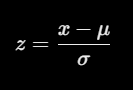

Onde \(x\) é o valor original, (mu) é a média do treinamento e (sigma) é o desvio-padrão calculado no treinamento.

O OneHotEncoder cria indicadores numéricos para cada categoria, sem impor uma ordem artificial entre elas.

# Unificar os tratamentos
Centraliza as transformações e reduz erros de preparação.

Utiliza o ColumnTransformer para aplicar automaticamente cada pipeline às colunas correspondentes.

In [7]:
from sklearn.compose import ColumnTransformer

preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, colunas_numericas),
        ("categoricas", pipeline_categorico, colunas_categoricas)
    ],
    remainder="drop"
)

print("Pré-processador criado com sucesso.")

Pré-processador criado com sucesso.


# Ajustar somente com o treinamento
Evita que informações estatísticas do conjunto de teste influenciem o treinamento.

Aprende as estatísticas e categorias utilizando somente X_treino. Em seguida, aplica as transformações ao treino e ao teste.

In [8]:
# Aprender as transformações somente com o treino
X_treino_preparado = preprocessador.fit_transform(X_treino)

# Aplicar ao teste sem reajustar
X_teste_preparado = preprocessador.transform(X_teste)

# Verificar as dimensões
print("Treino preparado:", X_treino_preparado.shape)
print("Teste preparado:", X_teste_preparado.shape)

# Conferir se há valores ausentes após as transformações
import numpy as np

for nome, matriz in [
    ("Treino", X_treino_preparado),
    ("Teste", X_teste_preparado)
]:
    valores = matriz.toarray() if hasattr(matriz, "toarray") else matriz

    print(
        f"{nome} contém NaN:",
        bool(np.isnan(valores).any())
    )

Treino preparado: (4000, 26)
Teste preparado: (1000, 26)
Treino contém NaN: False
Teste contém NaN: False


# Verificar a integridade dos dados preparados
Antes de treinar um modelo, precisamos garantir que a preparação não introduziu inconsistências ou eliminou registros inesperadamente.

Verifica se os conjuntos de treino e teste possuem a mesma quantidade de colunas, se não existem valores ausentes após o tratamento e se as linhas foram preservadas.

In [9]:
import numpy as np

# Verificar dimensões dos conjuntos
assert X_treino_preparado.shape[0] == len(y_treino)
assert X_teste_preparado.shape[0] == len(y_teste)

# Verificar compatibilidade das colunas
assert (
    X_treino_preparado.shape[1]
    == X_teste_preparado.shape[1]
)

# Verificar valores numéricos, incluindo NaN e infinito
for nome, matriz in [
    ("Treino", X_treino_preparado),
    ("Teste", X_teste_preparado)
]:
    valores = matriz.data if hasattr(matriz, "toarray") else matriz

    assert np.isfinite(valores).all(), (
        f"Valores inválidos encontrados em {nome}"
    )

print("Validação de integridade aprovada!")
print("Treino:", X_treino_preparado.shape)
print("Teste:", X_teste_preparado.shape)

Validação de integridade aprovada!
Treino: (4000, 26)
Teste: (1000, 26)


# Confirmar que não há Data Leakage

O desafio exige garantir que informações posteriores à concessão não influenciem a previsão de inadimplência.

Verifica se alguma variável proibida está presente no conjunto de treinamento ou teste.

In [10]:
# Variáveis que não podem ser usadas como preditoras
colunas_proibidas = {
    "id_cliente",
    "default_90d",
    "parcelas_pagas_ate_3m",
    "atraso_primeira_parcela_dias",
    "status_apos_90d",
    "juros_mensal_pct"
}

# Verificar as colunas utilizadas
vazamento_treino = colunas_proibidas.intersection(
    X_treino.columns
)

vazamento_teste = colunas_proibidas.intersection(
    X_teste.columns
)

assert not vazamento_treino, (
    f"Colunas proibidas no treino: {vazamento_treino}"
)

assert not vazamento_teste, (
    f"Colunas proibidas no teste: {vazamento_teste}"
)

print("Nenhuma coluna proibida encontrada.")

Nenhuma coluna proibida encontrada.


# Verificar os nomes das features transformadas
Precisamos entender como a preparação transforma as 17 variáveis candidatas em uma matriz numérica.

Apresenta os nomes das colunas que serão utilizadas pelos modelos após o One-Hot Encoding.

In [11]:
# Recuperar os nomes gerados pelo pré-processador
nomes_features = preprocessador.get_feature_names_out()

# Criar tabela de conferência
tabela_features = pd.DataFrame({
    "posicao": range(1, len(nomes_features) + 1),
    "feature": nomes_features
})

display(tabela_features)

print("Total de features:", len(nomes_features))

,posicao,feature
0,1,numericas__idade
1,2,numericas__renda_mensal
2,3,numericas__tempo_emprego_anos
3,4,numericas__autonomo
4,5,numericas__score_credito
5,6,numericas__valor_solicitado
6,7,numericas__prazo_meses
7,8,numericas__qtde_cartoes
8,9,numericas__qtde_contratos_abertos
9,10,numericas__utilizacao_credito


Total de features: 26


# Validar a função reutilizável
Garante que o código organizado na pasta src/ possa ser utilizado fora do notebook de experimentação.

Importa a função criada e verifica se ela retorna corretamente um pré-processador do Scikit-learn.

In [12]:
import sys

# Disponibilizar a raiz do projeto para importações
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.features.preprocessing import criar_preprocessador

# Criar um novo pré-processador não ajustado
novo_preprocessador = criar_preprocessador(X_treino)

print("Tipo:", type(novo_preprocessador).__name__)
print("Transformações:", novo_preprocessador.transformers)

Tipo: ColumnTransformer
Transformações: [('numericas', Pipeline(steps=[('imputacao', SimpleImputer(strategy='median')),
                ('padronizacao', StandardScaler())]), ['idade', 'renda_mensal', 'tempo_emprego_anos', 'autonomo', 'score_credito', 'valor_solicitado', 'prazo_meses', 'qtde_cartoes', 'qtde_contratos_abertos', 'utilizacao_credito', 'inadimplencias_anteriores', 'dias_atraso_max_12m', 'reclamacoes_6m', 'possui_avalista']), ('categoricas', Pipeline(steps=[('imputacao', SimpleImputer(strategy='most_frequent')),
                ('encoding', OneHotEncoder(handle_unknown='ignore'))]), ['canal_aquisicao', 'regiao', 'tipo_produto'])]
